# EDA
El conjunto de datos elegido para la actividad es el conjunto Adults(https://archive.ics.uci.edu/dataset/2/adult) de la Universidad de California en Irvine

## 1 Carga y Descripción del dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import mlflow
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score


In [2]:
# fetch dataset 
adult = fetch_ucirepo(id=2) 
  
# data (as pandas dataframes) 
X = adult.data.features 
y = adult.data.targets 

In [3]:
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   income  48842 non-null  str  
dtypes: str(1)
memory usage: 624.7 KB


In [4]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
dtypes: int64(6), str(8)
memory usage: 8.7 MB


Este dataset viene dividido desde el origen, cuenta con **48842** registros totales. La variable a predecir(y) es **income**, esta indica si los ingresos del individuo son mayores o, menores o iguales a 50k dólares; no tiene valores faltantes, y es de tipo categórica binaria que puede tomar los valores: >50K, <=50K. Las variables predictoras(X) se describen a continuación:
* **age**: Edad del individuo. Continua. 0 registros faltantes.
* **workclass**: Clase o sector de empleo al que pertenece la persona (ej. privado, gobierno, cuenta propia). Categórica. Sí contiene registros faltantes (comúnmente representados con "?").
* **fnlwgt**: Peso final (final weight), una estimación demográfica del censo sobre a cuántas personas de la población general representa ese registro específico. Continua. 0 registros faltantes.
* **education**: Nivel más alto de educación formal alcanzado. Categórica. 0 registros faltantes.
* **education-num**: Nivel de educación expresado como un valor numérico (donde un número mayor equivale a un mayor nivel educativo). Continua. 0 registros faltantes.
* **marital-status**: Estado civil actual del individuo. Categórica. 0 registros faltantes.
* **occupation**: Tipo de ocupación, oficio o profesión que desempeña. Categórica. Sí contiene registros faltantes (comúnmente representados con "?").
* **relationship**: Relación o rol de la persona dentro de su estructura o núcleo familiar (ej. esposo, hijo, no familiar). Categórica. 0 registros faltantes.
* **race**: Raza o grupo étnico del individuo. Categórica. 0 registros faltantes.
* **sex**: Sexo del individuo. Categórica. 0 registros faltantes.
* **capital-gain**: Ganancias de capital financiero reportadas por el individuo en dólares. Continua. 0 registros faltantes.
* **capital-loss**: Pérdidas de capital financiero reportadas en dólares. Continua. 0 registros faltantes.
* **hours-per-week**: Número de horas promedio trabajadas por semana. Continua. 0 registros faltantes.
* **native-country**: País de origen o nacimiento del individuo. Categórica. Sí contiene registros faltantes (comúnmente representados con "?").

## 2 EDA

In [5]:
X.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


Vemos que hay outliers en todas las variables predictoras numéricas excepto en education num, donde parece que no es tan alejado el valor máximo.

In [6]:
X.isnull().sum()

age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
dtype: int64

Observamos la cantidad exacta de valores faltantes que tenemos en el dataset, tenemos 2799 en workclass, 2809 en occupation y 857 en native-country. Si quisieramos eliminar los registros completos suponiendo que a los mismos registros a los que les falta occupation también les faltan workclass y native-country estaríamos eliminando alrededor de 6% de los datos.

In [7]:
# Se juntan X y Y para visualizar las relaciones entre X y Y
df = pd.concat([X, y], axis=1)

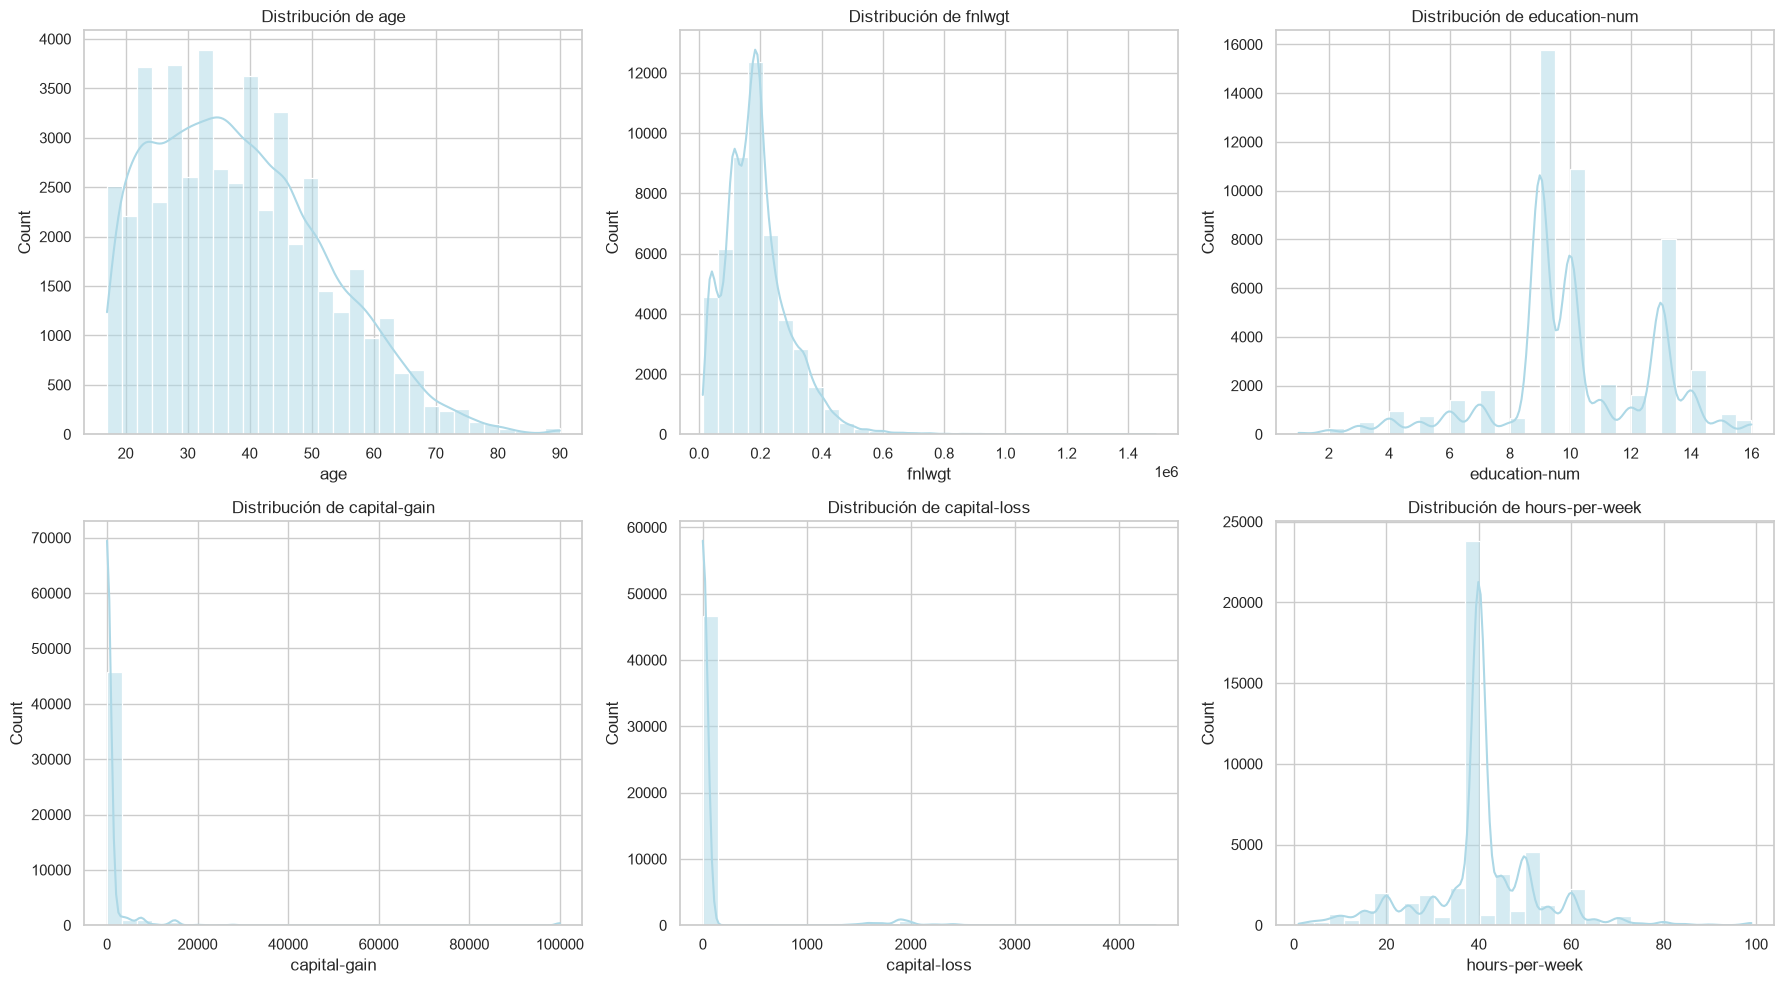

C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\1668335896.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='income', data=df, palette='viridis')


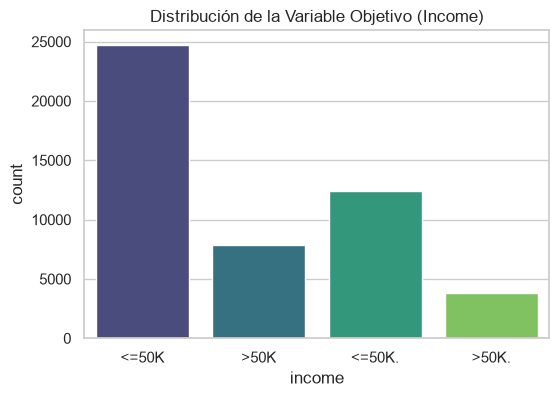

In [8]:
sns.set_theme(style="whitegrid")

# distribucion de variables numericas
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i//3, i%3], color='lightblue')
    axes[i//3, i%3].set_title(f'Distribución de {col}')

plt.tight_layout()
plt.show()

# Distribución de variable objetivo
plt.figure(figsize=(6, 4))
sns.countplot(x='income', data=df, palette='viridis')
plt.title('Distribución de la Variable Objetivo (Income)')
plt.show()

Con estas nuevas visualizaciones se pueden notar irregularidades en la distribución de todas las variables numéricas. Education-num y hours-per-week son las únicas variables que parecen tener una distribución medianamente normal. Las variables capital-gain, fnlwgt, capital-loss y age presentan sesgo a la izquierda esto significa diferentes cosas para cada tabla. Para age signica que la mayoría de las personas en la base de datos son menores de 50 años. Para capital-gain signica que solo una fracción muy pequeña de la población tiene ganancias, y unos pocos individuos tienen ganancias muy altas. Mientras que capital-loss significa que la mayor parte de la población no tiene pérdidas. Finalmente para fnlwgt la gráfica que se ve significa que la mayoría de los registros tienen pesos demográficos relativamente bajos a medios, pero hay unos pocos registros con pesos muy altos.

Con el gráfico de barras que hicimos logramos visualizar algo interesante, en primer lugar notamos que hay que corregir los valores de la variable a predecir, dado que tiene dos tipos de escritura para etiquetas con el mismo significado. Además se puede ver que más de 35,000 individuos de nuestra población de 48,842 registran ingresos menores a 50k.

C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\977484032.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='age', data=df, palette='Set2')


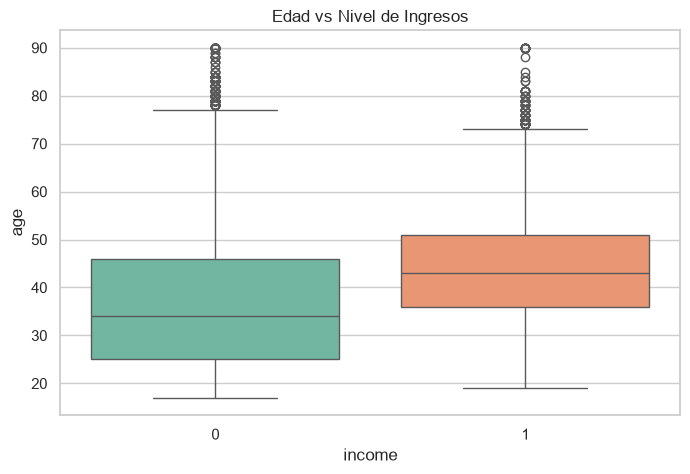

C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\977484032.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='hours-per-week', data=df, palette='Set2')


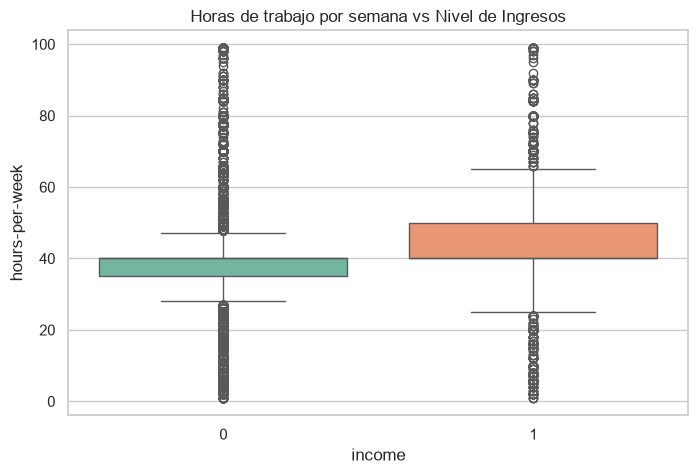

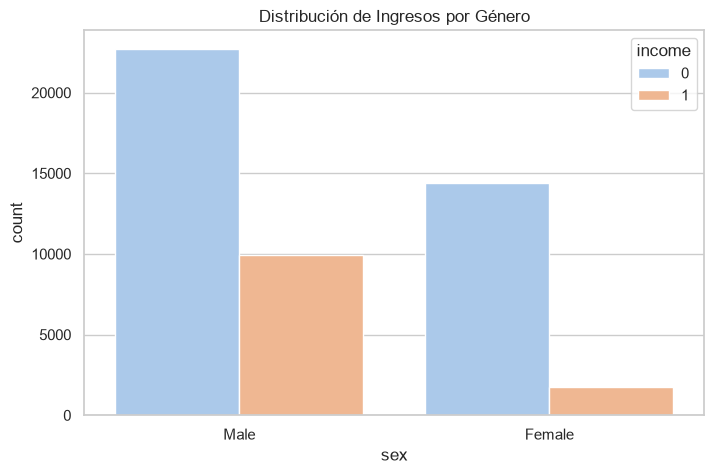

In [9]:
# Correcion de etiquetas, pasaremos de una vez a binario con el reemplazo:
df['income'] = df['income'].replace({"<=50K": int(0), "<=50K.": int(0), ">50K": int(1), ">50K.": int(1)})

# Edad vs Ingresos
plt.figure(figsize=(8, 5))
sns.boxplot(x='income', y='age', data=df, palette='Set2')
plt.title('Edad vs Nivel de Ingresos')
plt.show()

# Horas por semana vs Ingresos
plt.figure(figsize=(8, 5))
sns.boxplot(x='income', y='hours-per-week', data=df, palette='Set2')
plt.title('Horas de trabajo por semana vs Nivel de Ingresos')
plt.show()

# Género vs Ingresos
plt.figure(figsize=(8, 5))
sns.countplot(x='sex', hue='income', data=df, palette='pastel')
plt.title('Distribución de Ingresos por Género')
plt.show()

Se puede notar que en general para la variable edad, tanto en la población con ingresos mayores a 50k, las edades mayores 75 años son consideradas como datos atípicos. En la gráfica "horas de trabajo vs nivel de ingresos" también podemos notar algo interesante para quienes ganan menos de 50k lo normal es trabajar entre 30 y 50 horas, mientras que para quienes ganan más de 50k pueden trabajar hasta alrededor de 60 horas. Fuera de esos rangos vemos valores atípicos y en ambos casos vemos que hay valores atípicos.

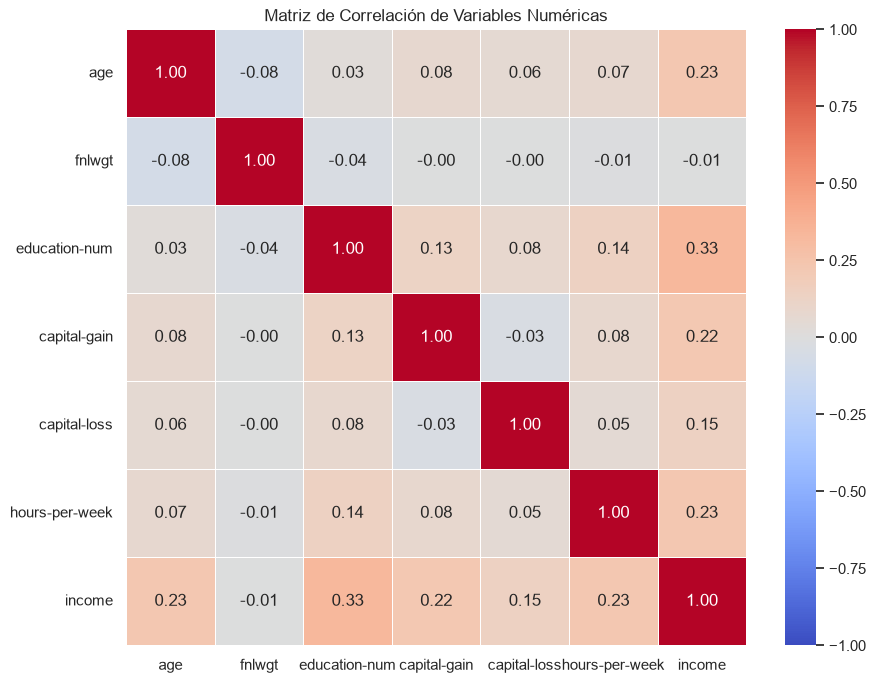

In [10]:
plt.figure(figsize=(10, 8))
# Calcular correlación de Pearson para variables numéricas
df['income'] = pd.to_numeric(df['income'])
corr = df.select_dtypes(include='number').corr()

# Generar un mapa de calor
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

No encontramos mucha relación entre las variables, por lo que realmente no hay necesidad de eliminar ninguna por correlación. Algo que se puede notar de esto es que la variable con menor correlación con income es fnlwgt
.